In [1]:
from pyprojroot import here
PROJECT_ROOT = here()
DATASET_DIR = PROJECT_ROOT / "Datasets" / "train"
DATASET_STAT_DIR = PROJECT_ROOT / "Datasets" / "statistics"
DATASET_STAT_DIR.mkdir(parents=True, exist_ok=True)
stat_file = DATASET_STAT_DIR / "train.csv"
stat_file.touch(exist_ok=True)

In [2]:
import csv
import soundfile as sf
from concurrent.futures import ThreadPoolExecutor

def get_file_info(wave_file):
    if wave_file.is_file() and wave_file.suffix.lower() in [".wav", ".flac"]:
        try:
            metadata = sf.info(wave_file)
            return [wave_file.name, metadata.frames]
        except Exception:
            return None
    return None


In [ ]:
wave_files = list(DATASET_DIR.iterdir())
with ThreadPoolExecutor() as executor:
    results = [res for res in executor.map(get_file_info, wave_files) if res]

with open(stat_file, mode="w", newline="", encoding="utf-8") as csvfile:

    writer = csv.writer(csvfile, )
    writer.writerow(["filename", "frames"])
    writer.writerows(results)


In [3]:
import polars as pl
import numpy as np

sampling_rate = 16000
df = pl.read_csv(stat_file)
frames = df["frames"].to_numpy()
durations = frames / sampling_rate
print(f"総録音時間：{durations.sum()/60/60:.2f}時間")



総録音時間：1290.81時間


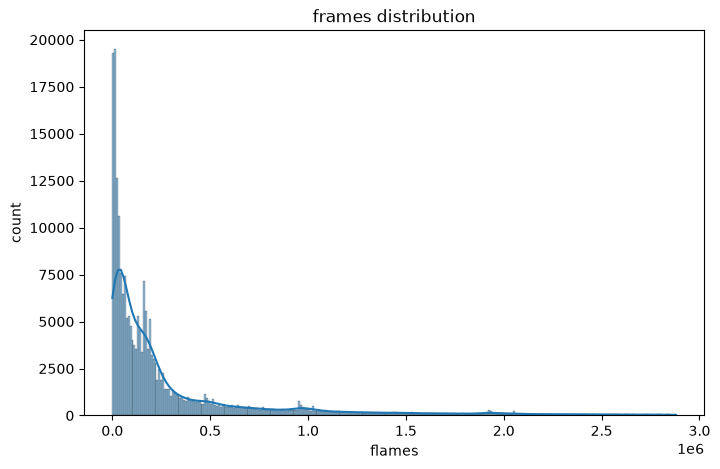

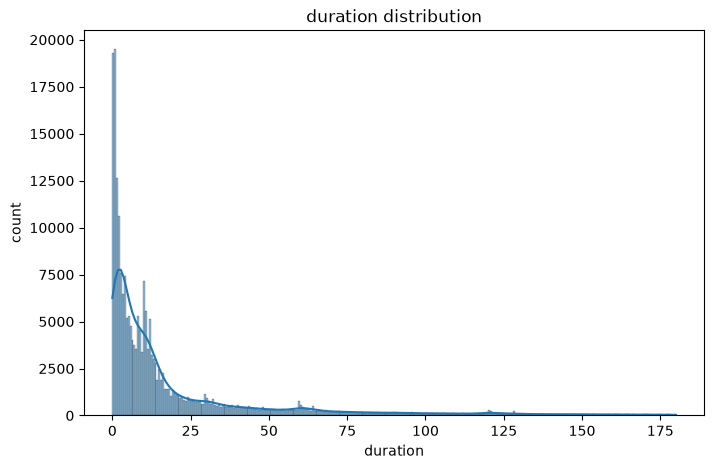

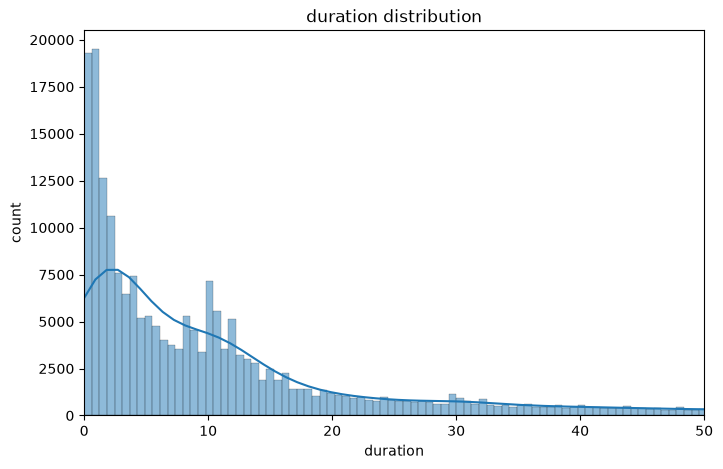

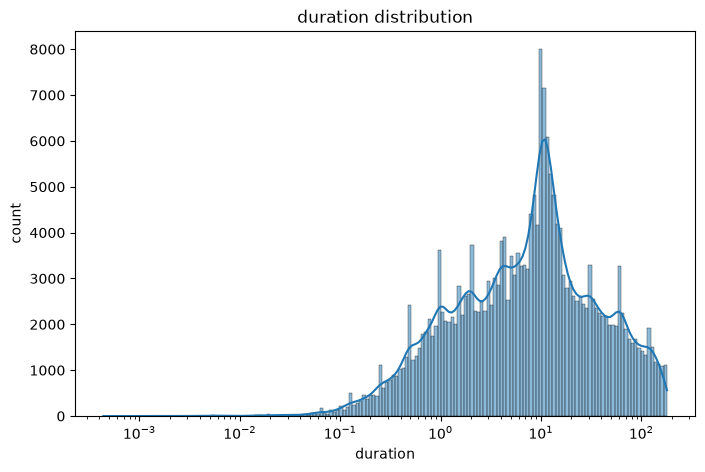

In [45]:
import matplotlib.pyplot as plt
import seaborn as sns


plt.figure(figsize=(8, 5))
sns.histplot(frames, kde=True)
plt.title("frames distribution")
plt.xlabel("flames")
plt.ylabel("count")
plt.show()
plt.figure(figsize=(8, 5))
sns.histplot(durations, kde=True)
plt.title("duration distribution")
plt.xlabel("duration")
plt.ylabel("count")
plt.show()
plt.figure(figsize=(8, 5))
sns.histplot(durations, kde=True)
plt.title("duration distribution")
plt.xlabel("duration")
plt.ylabel("count")
plt.xlim(0, 50)
plt.show()
plt.figure(figsize=(8, 5))
sns.histplot(durations, kde=True, log_scale=True)
plt.title("duration distribution")
plt.xlabel("duration")
plt.ylabel("count")
plt.show()

In [7]:
left = 6
right = 12
print(f"{left}s <= duration <= {right}sの音声の総録音時間：{np.sum(np.where((left <= durations) & (durations <= right), durations, 0))/60/60:.2f}h")
selected = np.where((left <= durations) & (durations <= right), True, False)
train = DATASET_STAT_DIR / "train.csv"
df.filter(selected).drop("frames").write_csv(train)

6s <= duration <= 12sの音声の総録音時間：112.18h


In [8]:
left = 20
right = 20.1
print(f"{left}s <= duration <= {right}sの音声の総録音時間：{np.sum(np.where((left <= durations) & (durations <= right), durations, 0))/60/60:.2f}h")
selected = np.where((left <= durations) & (durations <= right), True, False)
validation = DATASET_STAT_DIR / "validation.csv"
df.filter(selected).drop("frames").write_csv(validation)

20s <= duration <= 20.1sの音声の総録音時間：2.15h
